Notebook 05b — Confidence-Thresholded Trading with Minimum Holding Period

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import os
import glob
import time
import joblib
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")


Mounted at /content/drive


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/AI_Trading_Dissertation"
FINAL_PROJECT_PATH = PROJECT_PATH + "/Final_Project"

SPLITS_PATH = FINAL_PROJECT_PATH + "/02_Data/Splits"
MODELS_PATH = FINAL_PROJECT_PATH + "/03_Models"
RESULTS_PATH = FINAL_PROJECT_PATH + "/04_Results"
FIGURES_PATH = FINAL_PROJECT_PATH + "/05_Figures"

os.makedirs(FIGURES_PATH, exist_ok=True)

LABELS = ["Buy", "Hold", "Sell"]
SIGNAL_TO_POSITION = {"Buy": 1, "Hold": 0, "Sell": -1}
RANDOM_STATE = 42

PRIMARY_COST_BPS = 5
COST_LEVELS_BPS = [0, 2, 5, 10, 20]
RISK_FREE_ANNUAL = 0.065

INNER_TRAIN_FRACTION = 0.8   # of the training set; the rest becomes validation

# The search grid
CONFIDENCE_THRESHOLDS = [0.34, 0.40, 0.45, 0.50, 0.55, 0.60]
MIN_HOLD_BARS = [1, 4, 8, 16, 26]   # 26 bars ~ one full trading day

print("Grid size:", len(CONFIDENCE_THRESHOLDS) * len(MIN_HOLD_BARS), "configurations per model")


Grid size: 30 configurations per model


Load splits and rebuild the feature list

In [ ]:
train_files = sorted(glob.glob(os.path.join(SPLITS_PATH, "*_train.parquet")))
stock_names = [os.path.basename(f).replace("_train.parquet", "") for f in train_files]

_sample = pd.read_parquet(train_files[0])
EXCLUDE_FROM_FEATURES = {
    "datetime", "open", "high", "low", "close", "volume", "tick_count",
    "future_return", "target_threshold", "target_signal",
}
FEATURE_COLUMNS = [c for c in _sample.columns if c not in EXCLUDE_FROM_FEATURES]

# Bars per year, measured from the data (same method as Notebook 05)
_test_sample = pd.read_parquet(os.path.join(SPLITS_PATH, f"{stock_names[0]}_test.parquet"))
_span_days = (_test_sample["datetime"].max() - _test_sample["datetime"].min()).days
BARS_PER_YEAR = len(_test_sample) / _span_days * 365.25

print(f"{len(stock_names)} stocks, {len(FEATURE_COLUMNS)} features")
print(f"BARS_PER_YEAR = {BARS_PER_YEAR:.0f}")


10 stocks, 22 features
BARS_PER_YEAR = 6873


Turning probabilities into positions

Two gates in sequence:

- **Gate 1 (confidence):** if the highest class probability is below the threshold, force Hold.
- **Gate 2 (minimum hold):** walk forward bar by bar; once a non-zero position is opened, refuse to change it until `min_hold` bars have elapsed.

In [ ]:
def probabilities_to_positions(proba, classes, threshold, min_hold):
    """
    proba   : (n_bars, n_classes) predicted probabilities
    classes : array of class labels matching proba's columns
    returns : integer position array in {-1, 0, +1}, one per bar
    """
    best_idx = proba.argmax(axis=1)
    best_prob = proba.max(axis=1)
    raw_signal = classes[best_idx]

    # Gate 1: confidence
    desired = np.array([SIGNAL_TO_POSITION.get(s, 0) for s in raw_signal])
    desired[best_prob < threshold] = 0

    if min_hold <= 1:
        return desired

    # Gate 2: minimum holding period
    positions = np.zeros(len(desired), dtype=int)
    current = 0
    bars_held = 0

    for i in range(len(desired)):
        if current == 0:
            # Flat: free to open a position whenever one is desired
            current = desired[i]
            bars_held = 0 if current == 0 else 1
        else:
            bars_held += 1
            if bars_held >= min_hold and desired[i] != current:
                # Locked-in period served; allowed to switch or close
                current = desired[i]
                bars_held = 0 if current == 0 else 1
        positions[i] = current

    return positions


Backtest driven by a position array

In [ ]:
def backtest_positions(close, positions, cost_bps, bars_per_year=None):
    if bars_per_year is None:
        bars_per_year = BARS_PER_YEAR

    close = pd.Series(np.asarray(close, dtype=float))
    market_return = close.pct_change()

    # RULE 1: act only from the next bar onwards
    pos = pd.Series(positions).shift(1).fillna(0)

    turnover = pos.diff().abs().fillna(pos.abs())
    cost = turnover * (cost_bps / 10000.0)

    gross = pos * market_return
    net = gross - cost

    valid = market_return.notna()
    net = net[valid]
    gross = gross[valid]
    pos_v = pos[valid]
    mkt = market_return[valid]
    turn = turnover[valid]

    equity = (1 + net).cumprod()
    bh_equity = (1 + mkt).cumprod()

    total_return = equity.iloc[-1] - 1
    bh_return = bh_equity.iloc[-1] - 1

    years = len(net) / bars_per_year
    fe = equity.iloc[-1]
    cagr = fe ** (1 / years) - 1 if fe > 0 and years > 0 else np.nan

    rf_bar = RISK_FREE_ANNUAL / bars_per_year
    excess = net - rf_bar
    sharpe = (excess.mean() / excess.std()) * np.sqrt(bars_per_year) if excess.std() > 0 else np.nan

    max_dd = (equity / equity.cummax() - 1).min()

    traded = gross[pos_v != 0]
    win_rate = (traded > 0).mean() if len(traded) else np.nan

    return {
        "Total_Return": round(float(total_return), 4),
        "CAGR": round(float(cagr), 4) if not np.isnan(cagr) else np.nan,
        "Sharpe": round(float(sharpe), 3) if not np.isnan(sharpe) else np.nan,
        "Max_Drawdown": round(float(max_dd), 4),
        "BuyHold_Return": round(float(bh_return), 4),
        "Position_Changes": int((turn > 0).sum()),
        "Turnover_Units": round(float(turn.sum()), 1),
        "Time_In_Market": round(float((pos_v != 0).mean()), 3),
        "Win_Rate": round(float(win_rate), 4) if not np.isnan(win_rate) else np.nan,
        "N_Bars": int(len(net)),
    }, equity


Retraining on inner-train, getting validation probabilities


In [ ]:
validation_store = {}   # stock -> dict with close, and proba per model

overall_start = time.time()

for i, stock in enumerate(stock_names, 1):
    train_df = pd.read_parquet(os.path.join(SPLITS_PATH, f"{stock}_train.parquet"))

    cut = int(len(train_df) * INNER_TRAIN_FRACTION)
    inner_train = train_df.iloc[:cut]
    validation = train_df.iloc[cut:].reset_index(drop=True)

    X_in, y_in = inner_train[FEATURE_COLUMNS], inner_train["target_signal"]
    X_val = validation[FEATURE_COLUMNS]

    print(f"[{i}/{len(stock_names)}] {stock}: inner-train {X_in.shape}, validation {X_val.shape}")

    entry = {"close": validation["close"].values, "datetime": validation["datetime"].values}

    # --- Random Forest ---
    t0 = time.time()
    rf = RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=50,
        n_jobs=-1, random_state=RANDOM_STATE, class_weight="balanced_subsample",
    )
    rf.fit(X_in, y_in)
    entry["RandomForest"] = {"proba": rf.predict_proba(X_val), "classes": rf.classes_}
    print(f"    RF trained in {time.time() - t0:.0f}s")

    # --- XGBoost ---
    t0 = time.time()
    label_to_int = {l: k for k, l in enumerate(LABELS)}
    xgb = XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        random_state=RANDOM_STATE, n_jobs=-1,
        tree_method="hist", eval_metric="mlogloss",
    )
    xgb.fit(X_in, y_in.map(label_to_int))
    xgb_proba = xgb.predict_proba(X_val)
    # xgb.classes_ are integers 0..2 - map back to label strings in the same column order
    xgb_classes = np.array([LABELS[c] for c in xgb.classes_])
    entry["XGBoost"] = {"proba": xgb_proba, "classes": xgb_classes}
    print(f"    XGB trained in {time.time() - t0:.0f}s")

    validation_store[stock] = entry

print(f"\nInner-training complete in {(time.time() - overall_start) / 60:.1f} minutes.")


[1/10] Eicher_Motors: inner-train (46362, 22), validation (11591, 22)
    RF trained in 50s
    XGB trained in 12s
[2/10] HDFCB: inner-train (46675, 22), validation (11669, 22)
    RF trained in 47s
    XGB trained in 12s
[3/10] Hindustan_Unilever: inner-train (46646, 22), validation (11662, 22)
    RF trained in 46s
    XGB trained in 12s
[4/10] ICICIBC: inner-train (46739, 22), validation (11685, 22)
    RF trained in 46s
    XGB trained in 12s
[5/10] INFOSYS: inner-train (46742, 22), validation (11686, 22)
    RF trained in 47s
    XGB trained in 13s
[6/10] ITC: inner-train (46738, 22), validation (11685, 22)
    RF trained in 46s
    XGB trained in 12s
[7/10] Mahindra_and_Mahindra: inner-train (46680, 22), validation (11670, 22)
    RF trained in 46s
    XGB trained in 11s
[8/10] ONGC: inner-train (46746, 22), validation (11687, 22)
    RF trained in 43s
    XGB trained in 11s
[9/10] Reliance: inner-train (46745, 22), validation (11687, 22)
    RF trained in 45s
    XGB trained in 

Searching the grid on VALIDATION only


In [ ]:
val_rows = []

for model_name in ["RandomForest", "XGBoost"]:
    for threshold in CONFIDENCE_THRESHOLDS:
        for min_hold in MIN_HOLD_BARS:
            per_stock_metrics = []

            for stock, entry in validation_store.items():
                info = entry[model_name]
                positions = probabilities_to_positions(
                    info["proba"], info["classes"], threshold, min_hold
                )
                m, _ = backtest_positions(entry["close"], positions, PRIMARY_COST_BPS)
                per_stock_metrics.append(m)

            avg = pd.DataFrame(per_stock_metrics).mean(numeric_only=True)
            val_rows.append({
                "Model": model_name,
                "Threshold": threshold,
                "Min_Hold": min_hold,
                "Val_Return": round(avg["Total_Return"], 4),
                "Val_Sharpe": round(avg["Sharpe"], 3),
                "Val_MaxDD": round(avg["Max_Drawdown"], 4),
                "Val_Turnover": round(avg["Turnover_Units"], 1),
                "Val_TimeInMkt": round(avg["Time_In_Market"], 3),
            })

val_df = pd.DataFrame(val_rows)
val_df.to_csv(os.path.join(RESULTS_PATH, "Threshold_Search_Validation.csv"), index=False)

print("Top 15 configurations on VALIDATION, ranked by Sharpe:\n")
val_df.sort_values("Val_Sharpe", ascending=False).head(15)


Top 15 configurations on VALIDATION, ranked by Sharpe:



,Model,Threshold,Min_Hold,Val_Return,Val_Sharpe,Val_MaxDD,Val_Turnover,Val_TimeInMkt
19,RandomForest,0.50,26,0.0489,-0.533,-0.1571,285.4,0.306
14,RandomForest,0.45,26,-0.0222,-0.554,-0.2646,707.7,0.770
18,RandomForest,0.50,16,0.0202,-0.731,-0.1467,289.2,0.186
9,RandomForest,0.40,26,-0.1410,-0.765,-0.3433,748.5,0.891
44,XGBoost,0.45,26,-0.2228,-0.960,-0.3684,760.4,0.918
17,RandomForest,0.50,8,-0.0048,-0.962,-0.1367,292.6,0.088
59,XGBoost,0.60,26,-0.1608,-0.996,-0.2618,542.8,0.597
39,XGBoost,0.40,26,-0.2291,-1.028,-0.3624,751.2,0.949
34,XGBoost,0.34,26,-0.2701,-1.072,-0.4073,756.4,0.978
49,XGBoost,0.50,26,-0.2333,-1.107,-0.3734,758.4,0.878


In [ ]:
# Lock in the single best configuration per model - chosen on validation, never on test
best_config = {}

for model_name in ["RandomForest", "XGBoost"]:
    sub = val_df[val_df["Model"] == model_name].sort_values("Val_Sharpe", ascending=False)
    row = sub.iloc[0]
    best_config[model_name] = {"threshold": row["Threshold"], "min_hold": int(row["Min_Hold"])}
    print(f"{model_name}: threshold={row['Threshold']}, min_hold={row['Min_Hold']} "
          f"(validation Sharpe {row['Val_Sharpe']}, return {row['Val_Return']:.2%}, turnover {row['Val_Turnover']:.0f})")

print("\nThese parameters are now FIXED. The test set is evaluated once, below.")


RandomForest: threshold=0.5, min_hold=26 (validation Sharpe -0.533, return 4.89%, turnover 285)
XGBoost: threshold=0.45, min_hold=26 (validation Sharpe -0.96, return -22.28%, turnover 760)

These parameters are now FIXED. The test set is evaluated once, below.


In [ ]:
test_rows = []
test_equity_curves = {}

for stock in stock_names:
    test_df = pd.read_parquet(os.path.join(SPLITS_PATH, f"{stock}_test.parquet"))
    X_test = test_df[FEATURE_COLUMNS]
    close = test_df["close"].values

    # --- Random Forest (saved by Notebook 04) ---
    rf = joblib.load(os.path.join(MODELS_PATH, "RandomForest", f"{stock}_rf.joblib"))
    rf_proba = rf.predict_proba(X_test)
    cfg = best_config["RandomForest"]
    rf_pos = probabilities_to_positions(rf_proba, rf.classes_, cfg["threshold"], cfg["min_hold"])

    # --- XGBoost (saved by Notebook 04) ---
    xgb = XGBClassifier()
    xgb.load_model(os.path.join(MODELS_PATH, "XGBoost", f"{stock}_xgb.json"))
    xgb_proba = xgb.predict_proba(X_test)
    xgb_classes = np.array([LABELS[c] for c in range(xgb_proba.shape[1])])
    cfg_x = best_config["XGBoost"]
    xgb_pos = probabilities_to_positions(xgb_proba, xgb_classes, cfg_x["threshold"], cfg_x["min_hold"])

    for model_name, positions in [("RandomForest", rf_pos), ("XGBoost", xgb_pos)]:
        for cost in COST_LEVELS_BPS:
            m, equity = backtest_positions(close, positions, cost)
            m.update({"Stock": stock, "Model": model_name, "Cost_BPS": cost})
            test_rows.append(m)
            if cost == PRIMARY_COST_BPS:
                test_equity_curves[(stock, model_name)] = (test_df["datetime"].values[1:], equity.values)

    rf_m = [r for r in test_rows if r["Stock"] == stock and r["Model"] == "RandomForest" and r["Cost_BPS"] == PRIMARY_COST_BPS][0]
    print(f"{stock:24s} RF  ret={rf_m['Total_Return']:>8.2%}  sharpe={rf_m['Sharpe']:>7}  "
          f"turnover={rf_m['Turnover_Units']:>7.0f}  inMkt={rf_m['Time_In_Market']:.2f}")

test_df_results = pd.DataFrame(test_rows)
test_df_results.to_csv(os.path.join(RESULTS_PATH, "Backtest_Thresholded_Test.csv"), index=False)
print("\nSaved thresholded test results.")


Eicher_Motors            RF  ret=  -8.80%  sharpe= -2.428  turnover=     54  inMkt=0.05
HDFCB                    RF  ret=  -5.45%  sharpe= -0.891  turnover=     76  inMkt=0.07
Hindustan_Unilever       RF  ret=   9.81%  sharpe= -0.101  turnover=    417  inMkt=0.36
ICICIBC                  RF  ret=   0.00%  sharpe=-2314031349910678.5  turnover=      0  inMkt=0.00
INFOSYS                  RF  ret= -14.84%  sharpe= -0.675  turnover=    484  inMkt=0.41
ITC                      RF  ret= -12.02%  sharpe= -0.795  turnover=    625  inMkt=0.54
Mahindra_and_Mahindra    RF  ret=   5.38%  sharpe= -0.369  turnover=    154  inMkt=0.13
ONGC                     RF  ret= -28.93%  sharpe=  -1.04  turnover=    661  inMkt=0.57
Reliance                 RF  ret= -10.56%  sharpe= -0.912  turnover=    441  inMkt=0.38
TCS                      RF  ret= -32.91%  sharpe= -1.658  turnover=    371  inMkt=0.32

Saved thresholded test results.


The before/after comparison

In [ ]:
original = pd.read_csv(os.path.join(RESULTS_PATH, "Backtest_Results_Full.csv"))
orig_primary = original[original["Cost_BPS"] == PRIMARY_COST_BPS]
new_primary = test_df_results[test_df_results["Cost_BPS"] == PRIMARY_COST_BPS]

comparison_rows = []
for model_name in ["RandomForest", "XGBoost"]:
    o = orig_primary[orig_primary["Model"] == model_name]
    n = new_primary[new_primary["Model"] == model_name]
    cfg = best_config[model_name]

    comparison_rows.append({
        "Model": model_name,
        "Version": "Original (trade every bar)",
        "Threshold": "-", "Min_Hold": "-",
        "Total_Return": round(o["Total_Return"].mean(), 4),
        "Sharpe": round(o["Sharpe"].mean(), 3),
        "Max_Drawdown": round(o["Max_Drawdown"].mean(), 4),
        "Turnover_Units": round(o["Total_Cost_Paid"].mean() / (PRIMARY_COST_BPS / 10000), 1),
        "Time_In_Market": round(o["Time_In_Market"].mean(), 3),
    })
    comparison_rows.append({
        "Model": model_name,
        "Version": "Thresholded + min-hold",
        "Threshold": cfg["threshold"], "Min_Hold": cfg["min_hold"],
        "Total_Return": round(n["Total_Return"].mean(), 4),
        "Sharpe": round(n["Sharpe"].mean(), 3),
        "Max_Drawdown": round(n["Max_Drawdown"].mean(), 4),
        "Turnover_Units": round(n["Turnover_Units"].mean(), 1),
        "Time_In_Market": round(n["Time_In_Market"].mean(), 3),
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(os.path.join(RESULTS_PATH, "Backtest_Before_After.csv"), index=False)
print(f"Averaged across {len(stock_names)} stocks, at {PRIMARY_COST_BPS} bps per side:\n")
comparison_df


Averaged across 10 stocks, at 5 bps per side:



,Model,Version,Threshold,Min_Hold,Total_Return,Sharpe,Max_Drawdown,Turnover_Units,Time_In_Market
0,RandomForest,Original (trade every bar),-,-,-0.7871,-4.183000e+00,-0.8060,4670.5,0.658
1,RandomForest,Thresholded + min-hold,0.5,26,-0.0983,-2.314031e+14,-0.2219,328.3,0.282
2,XGBoost,Original (trade every bar),-,-,-0.9113,-5.452000e+00,-0.9146,5750.6,0.828
3,XGBoost,Thresholded + min-hold,0.45,26,-0.4049,-1.348000e+00,-0.5033,995.1,0.899


Cost sensitivity, before and after

In [ ]:
new_cost = (
    test_df_results.groupby(["Model", "Cost_BPS"])["Total_Return"].mean().unstack().round(4)
)
new_cost.columns = [f"{c}bps" for c in new_cost.columns]
new_cost.to_csv(os.path.join(RESULTS_PATH, "Cost_Sensitivity_Thresholded.csv"))

print("THRESHOLDED strategy - average total return by cost level:")
display(new_cost)

old_cost = (
    original[original["Model"].isin(["RandomForest", "XGBoost"])]
    .groupby(["Model", "Cost_BPS"])["Total_Return"].mean().unstack().round(4)
)
old_cost.columns = [f"{c}bps" for c in old_cost.columns]
print("\nORIGINAL strategy (for comparison):")
display(old_cost)


THRESHOLDED strategy - average total return by cost level:


,0bps,2bps,5bps,10bps,20bps
Model,,,,,
RandomForest,0.0609,-0.0074,-0.0983,-0.2238,-0.4028
XGBoost,-0.0208,-0.1976,-0.4049,-0.6384,-0.8666



ORIGINAL strategy (for comparison):


,0bps,2bps,5bps,10bps,20bps
Model,,,,,
RandomForest,1.0093,-0.2048,-0.7871,-0.9718,-0.9992
XGBoost,0.5432,-0.5144,-0.9113,-0.9943,-1.0000


Full test-set grid

In [ ]:
sensitivity_rows = []

for stock in stock_names:
    test_df = pd.read_parquet(os.path.join(SPLITS_PATH, f"{stock}_test.parquet"))
    X_test = test_df[FEATURE_COLUMNS]
    close = test_df["close"].values

    rf = joblib.load(os.path.join(MODELS_PATH, "RandomForest", f"{stock}_rf.joblib"))
    rf_proba = rf.predict_proba(X_test)

    for threshold in CONFIDENCE_THRESHOLDS:
        for min_hold in MIN_HOLD_BARS:
            positions = probabilities_to_positions(rf_proba, rf.classes_, threshold, min_hold)
            m, _ = backtest_positions(close, positions, PRIMARY_COST_BPS)
            sensitivity_rows.append({
                "Stock": stock, "Threshold": threshold, "Min_Hold": min_hold,
                "Total_Return": m["Total_Return"], "Sharpe": m["Sharpe"],
                "Turnover_Units": m["Turnover_Units"],
            })

sens_df = pd.DataFrame(sensitivity_rows)
sens_grid = sens_df.groupby(["Threshold", "Min_Hold"])["Total_Return"].mean().unstack().round(4)
sens_df.to_csv(os.path.join(RESULTS_PATH, "Threshold_Sensitivity_Test.csv"), index=False)

chosen = best_config["RandomForest"]
print(f"Random Forest - average test return across the full grid.")
print(f"Validation selected: threshold={chosen['threshold']}, min_hold={chosen['min_hold']}\n")
sens_grid


Random Forest - average test return across the full grid.
Validation selected: threshold=0.5, min_hold=26



Min_Hold,1,4,8,16,26
Threshold,,,,,
0.34,-0.7849,-0.6965,-0.6022,-0.3979,-0.2265
0.40,-0.6262,-0.5571,-0.4061,-0.3269,-0.2176
0.45,-0.2980,-0.3076,-0.2917,-0.2670,-0.2608
0.50,-0.1016,-0.1106,-0.1096,-0.0853,-0.0983
0.55,-0.0112,-0.0075,-0.0136,0.0103,0.0110
0.60,0.0046,-0.0002,-0.0007,-0.0011,-0.0028


Charts

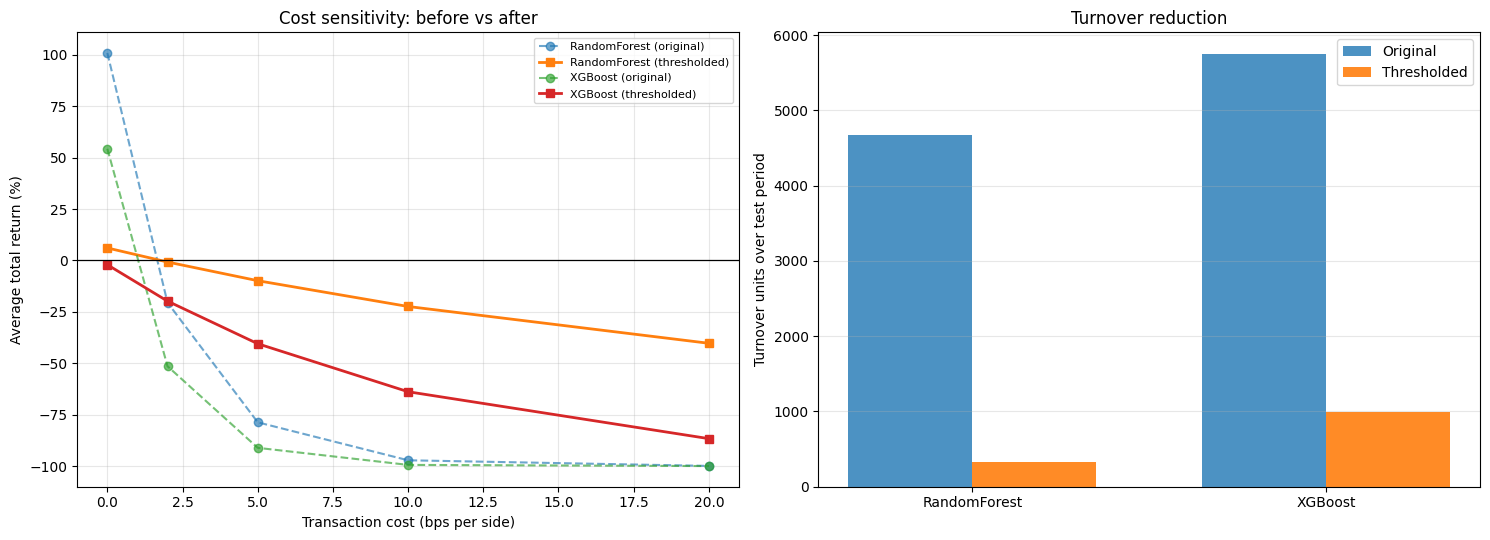

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: cost sensitivity, original vs thresholded
ax = axes[0]
for model_name in ["RandomForest", "XGBoost"]:
    o = original[original["Model"] == model_name].groupby("Cost_BPS")["Total_Return"].mean()
    n = test_df_results[test_df_results["Model"] == model_name].groupby("Cost_BPS")["Total_Return"].mean()
    ax.plot(o.index, o.values * 100, marker="o", linestyle="--", alpha=0.65, label=f"{model_name} (original)")
    ax.plot(n.index, n.values * 100, marker="s", linewidth=2, label=f"{model_name} (thresholded)")

ax.axhline(0, color="black", linewidth=0.9)
ax.set_xlabel("Transaction cost (bps per side)")
ax.set_ylabel("Average total return (%)")
ax.set_title("Cost sensitivity: before vs after")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# Right: turnover reduction
ax = axes[1]
models = ["RandomForest", "XGBoost"]
orig_turn = [original[(original["Model"] == m) & (original["Cost_BPS"] == PRIMARY_COST_BPS)]["Total_Cost_Paid"].mean() / (PRIMARY_COST_BPS / 10000) for m in models]
new_turn = [test_df_results[(test_df_results["Model"] == m) & (test_df_results["Cost_BPS"] == PRIMARY_COST_BPS)]["Turnover_Units"].mean() for m in models]

x = np.arange(len(models)); width = 0.35
ax.bar(x - width / 2, orig_turn, width, label="Original", alpha=0.8)
ax.bar(x + width / 2, new_turn, width, label="Thresholded", alpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(models)
ax.set_ylabel("Turnover units over test period")
ax.set_title("Turnover reduction")
ax.legend()
ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "thresholded_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()


Best thresholded model: XGBoost


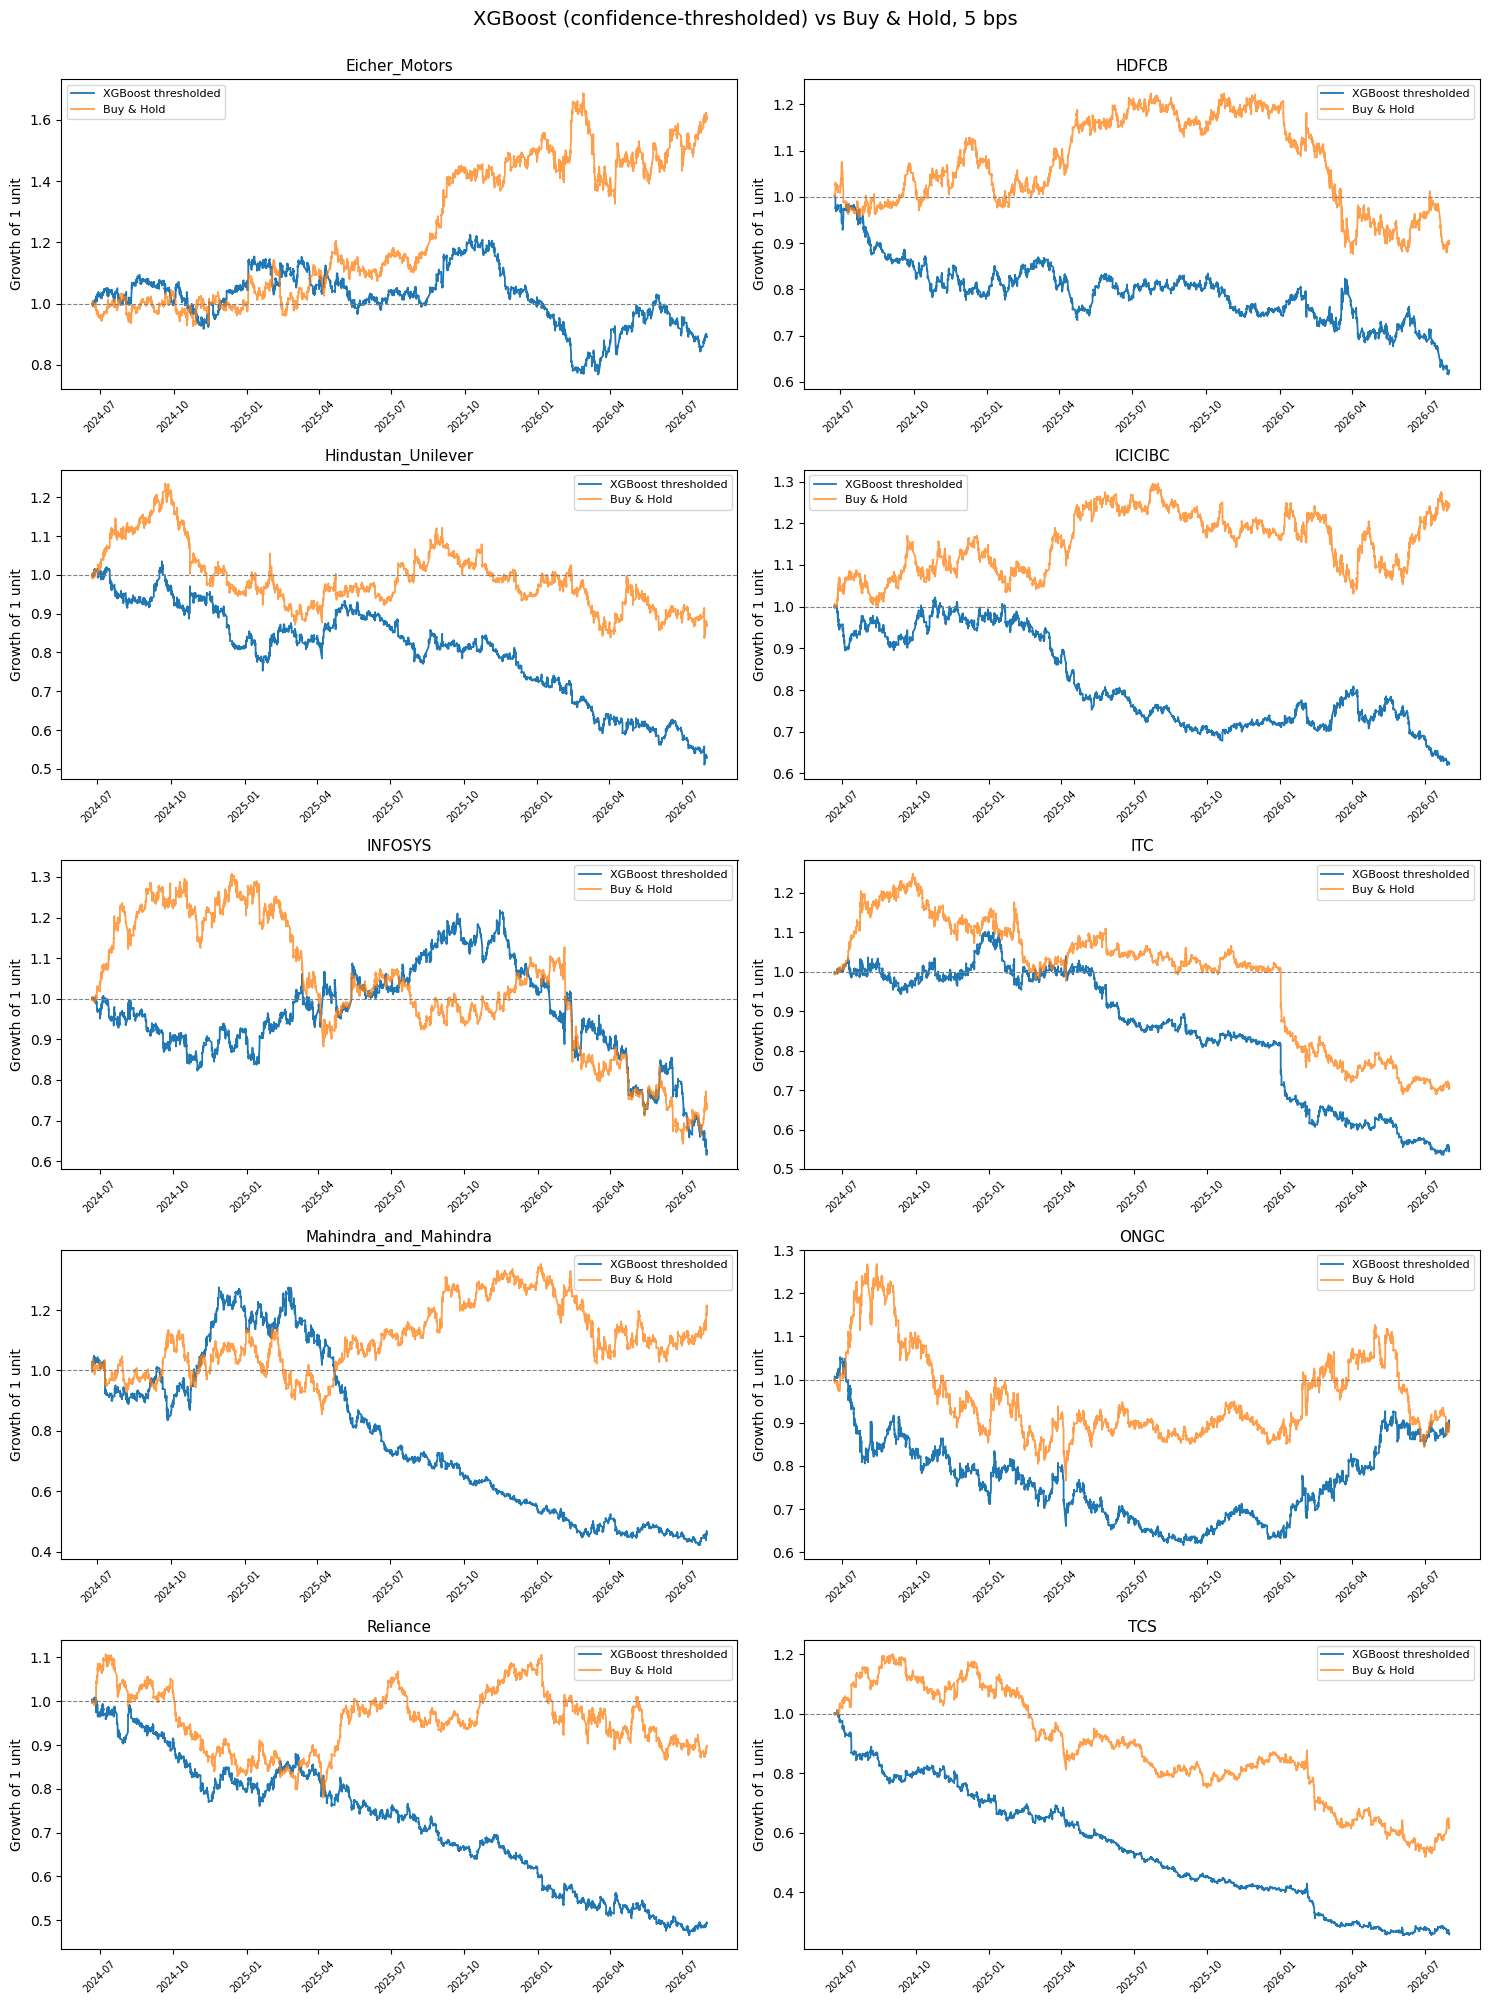

In [ ]:
# Equity curves for the thresholded best model
best_overall = comparison_df[comparison_df["Version"] == "Thresholded + min-hold"].sort_values("Sharpe", ascending=False).iloc[0]["Model"]
print("Best thresholded model:", best_overall)

fig, axes = plt.subplots(5, 2, figsize=(15, 20))
axes = axes.flatten()

for idx, stock in enumerate(stock_names):
    ax = axes[idx]
    dt, eq = test_equity_curves[(stock, best_overall)]
    test_df = pd.read_parquet(os.path.join(SPLITS_PATH, f"{stock}_test.parquet"))
    bh = (1 + pd.Series(test_df["close"].values).pct_change().dropna()).cumprod().values

    ax.plot(dt, eq, label=f"{best_overall} thresholded", linewidth=1.3)
    ax.plot(dt, bh, label="Buy & Hold", linewidth=1.3, alpha=0.75)
    ax.axhline(1.0, color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(stock, fontsize=11)
    ax.set_ylabel("Growth of 1 unit")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", rotation=45, labelsize=7)

for j in range(len(stock_names), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(f"{best_overall} (confidence-thresholded) vs Buy & Hold, {PRIMARY_COST_BPS} bps", fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, f"equity_thresholded_{best_overall}.png"), dpi=150, bbox_inches="tight")
plt.show()
